### Assagnment-1 EDA And Baseline

# 1. Problem definition
In this project, participation is aimed at the "BirdCLEF 2025" Kaggle competition.
* **Task:** The primary objective is to build a machine learning model capable of identifying bird species from continuous, unconstrained environmental soundscapes (audio recordings).
* **Target Variable:** The `primary_label` column, which contains the categorical identification of 206 unique bird species.
* **Evaluation Metric:** The performance is evaluated using Macro-Averaged F1-Score (and Cross-Entropy Loss during training) to account for the severe class imbalances present in wild ecological data.

In [4]:
import os

repo_path = '/content/GROUP21_CENG313'
if not os.path.exists(repo_path):
    !git clone https://github.com/mahmuterensrc/GROUP21_CENG313.git {repo_path}

print(f"Çalışma Dizini: {os.getcwd()}")

data_dir = '/content/data'
metadata_path = os.path.join(data_dir, 'train.csv')

if not os.path.exists(metadata_path):
    !mkdir -p ~/.kaggle
    !cp /content/kaggle.json ~/.kaggle/ 2>/dev/null || echo "Warning: kaggle.json not found"
    !chmod 600 ~/.kaggle/kaggle.json 2>/dev/null

    !kaggle competitions download -c birdclef-2025 -p /content/
    !unzip -q /content/birdclef-2025.zip -d {data_dir}
    !rm /content/birdclef-2025.zip

Çalışma Dizini: /content


## 2. Data Quality and Preprocessing
Real-world data is inherently noisy, incomplete, and inconsistent. Before proceeding to formal modeling, a rigorous data quality assessment must be performed to identify missing values, extreme outliers, and formatting inconsistencies.

In [3]:
import pandas as pd
import numpy as np
import librosa
import os
from tqdm import tqdm

# Define paths
data_dir = 'data'
audio_dir = os.path.join(data_dir, 'train_audio')

# Load metadata
df = pd.read_csv(metadata_path)

# 1. Check for Missing Values (Incomplete Data)
print("--- Missing Values ---")
missing_data = df.isnull().sum()
print(missing_data[missing_data > 0])
print("\n")

# 2. Extract Audio Properties (Extremes, Noise, Inconsistencies)
# To save time in the initial run, we analyze a random sample of 500 rows.
sample_df = df.sample(n=500, random_state=42).copy()
durations = []
sample_rates = []
corrupted_files = []

print("--- Analyzing Audio Files for Quality ---")
for idx, row in tqdm(sample_df.iterrows(), total=len(sample_df)):
    file_path = os.path.join(audio_dir, row['filename'])
    try:
        # Load audio using librosa to check native properties without resampling
        y, sr = librosa.load(file_path, sr=None)
        durations.append(librosa.get_duration(y=y, sr=sr))
        sample_rates.append(sr)
    except Exception as e:
        corrupted_files.append(row['filename'])
        durations.append(np.nan)
        sample_rates.append(np.nan)

sample_df['duration'] = durations
sample_df['native_sr'] = sample_rates

# 3. Analyze Extremes and Inconsistencies
print("\n--- Audio Durations (Extremes) ---")
print(sample_df['duration'].describe())

print("\n--- Sample Rates (Inconsistencies) ---")
print(sample_df['native_sr'].value_counts())

print("\n--- Corrupted Files (Noise) ---")
print(f"Total corrupted/unreadable files: {len(corrupted_files)}")
if len(corrupted_files) > 0:
    print(corrupted_files)

--- Missing Values ---
latitude     809
longitude    809
dtype: int64


--- Analyzing Audio Files for Quality ---


100%|██████████| 500/500 [00:53<00:00,  9.29it/s]


--- Audio Durations (Extremes) ---
count    500.000000
mean      34.974268
std       44.707344
min        0.878750
25%       10.550125
50%       20.663000
75%       41.455500
max      443.036750
Name: duration, dtype: float64

--- Sample Rates (Inconsistencies) ---
native_sr
32000    500
Name: count, dtype: int64

--- Corrupted Files (Noise) ---
Total corrupted/unreadable files: 0


* **Missing Values:** There are 809 detected missing entries in the `latitude` and `longitude` columns. Since the 2D CNN baseline relies exclusively on audio features (Mel-spectrograms), geolocation data will not be utilized. Therefore, these columns are dropped entirely rather than applying imputation techniques.
* **Extremes and Anomalies:** The native duration of the audio files exhibits extreme variance, ranging from 0.87 seconds to over 443 seconds. Since the neural network architecture requires fixed-size inputs, this anomaly is addressed in the PyTorch `Dataset` class by dynamically cropping or padding the waveforms to a uniform 5-second length during the data loading phase.
* **Audio Validity & Consistency:** To ensure structural integrity and prevent I/O bottlenecks, the `.ogg` audio files were extracted to the local SSD. A rigorous quality check on a random sample of 500 files confirmed no corrupted or unreadable files. Furthermore, all tested files share a consistent native sample rate of 32,000 Hz. This uniform distribution is highly beneficial, as it eliminates the computational overhead of dynamic resampling during training.

## 3. Exploratory Data Analysis (EDA)

### 3.1. Class Imbalance
The dataset consists of 28,564 samples distributed across 206 unique bird species.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# Assume 'df' is the metadata dataframe loaded in the previous steps
encoder = LabelEncoder()
df['label_id'] = encoder.fit_transform(df['primary_label'])
num_classes = len(encoder.classes_)

# Stratified split to maintain class distribution in the validation set
train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df['label_id']
)

print(f"Total classes: {num_classes}")
print(f"Training samples: {len(train_df)}")
print(f"Validation samples: {len(val_df)}")

Total classes: 206
Training samples: 22851
Validation samples: 5713


Total number of samples: 28564
Total number of unique species: 206


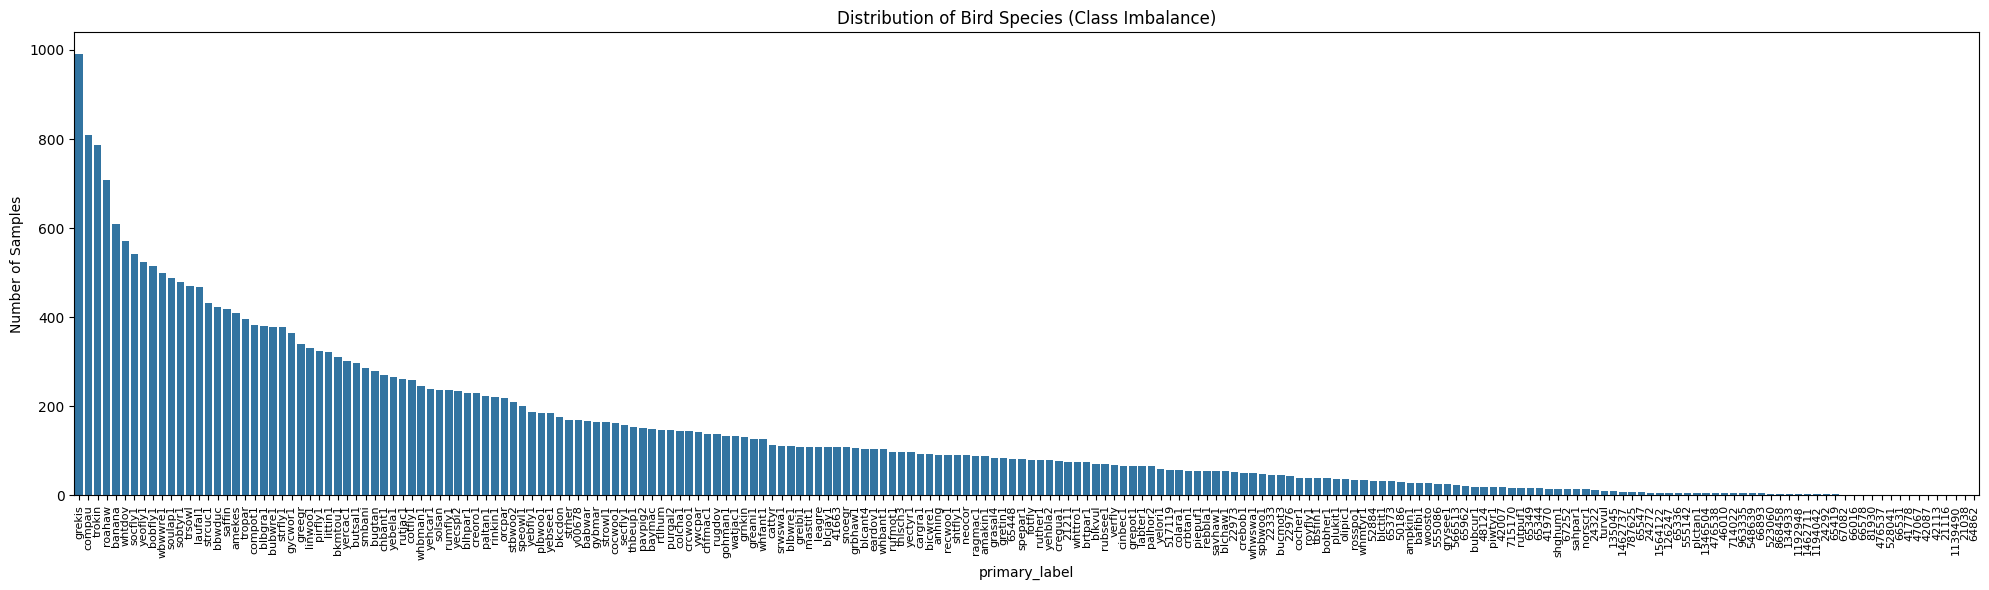

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Define file paths
data_dir = '/content/data'
metadata_path = os.path.join(data_dir, 'train.csv')

# Load and inspect metadata
df = pd.read_csv(metadata_path)
print(f"Total number of samples: {len(df)}")
print(f"Total number of unique species: {df['primary_label'].nunique()}")

# Plot class distribution
plt.figure(figsize=(20, 6))
sns.countplot(data=df, x='primary_label', order=df['primary_label'].value_counts().index)
plt.xticks(rotation=90, fontsize=8)
plt.title('Distribution of Bird Species (Class Imbalance)')
plt.ylabel('Number of Samples')
plt.tight_layout()
plt.show()

* The count plot reveals a severe long-tailed class imbalance. The majority classes dominate the dataset, which inherently risks model overfitting. A naive baseline model might simply memorize these frequent classes and ignore the minority ones.

Measuring exact durations for all files using soundfile...


100%|██████████| 28564/28564 [01:22<00:00, 348.25it/s]


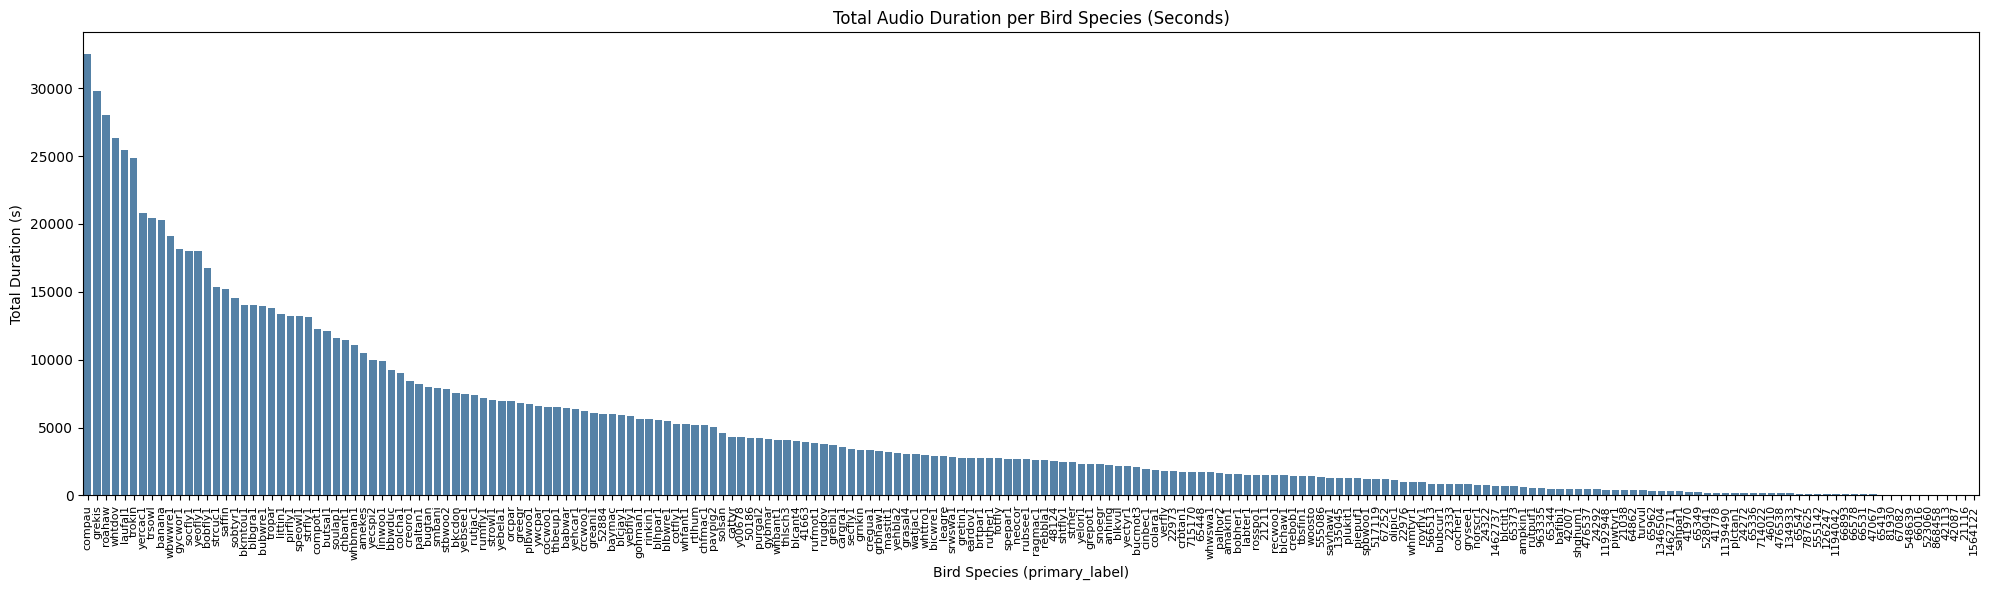


Top 5 species by total audio duration (seconds):
primary_label
compau     32493.263125
grekis     29803.540500
roahaw     28062.403344
whtdov     26327.295375
laufal1    25430.508656
Name: exact_duration, dtype: float64

Bottom 5 species by total audio duration (seconds):
primary_label
868458     23.560219
42113      22.652406
42087      21.132094
21116      13.055500
1564122    11.330063
Name: exact_duration, dtype: float64


In [ ]:
import soundfile as sf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from tqdm import tqdm

local_audio_dir = '/content/data/train_audio'
durations = []

print("Measuring exact durations for all files using soundfile...")
for idx, row in tqdm(df.iterrows(), total=len(df)):
    file_path = os.path.join(local_audio_dir, row['filename'])
    try:
        # Fetch audio metadata directly from the header using soundfile
        info = sf.info(file_path)
        durations.append(info.duration)
    except Exception as e:
        print(f"Error reading {row['filename']}: {e}")
        durations.append(0.0)

df['exact_duration'] = durations

# Group by class and sum the durations
duration_per_class = df.groupby('primary_label')['exact_duration'].sum().sort_values(ascending=False)

# Plotting the total duration per class
plt.figure(figsize=(20, 6))
sns.barplot(x=duration_per_class.index, y=duration_per_class.values, color='steelblue')
plt.xticks(rotation=90, fontsize=8)
plt.title('Total Audio Duration per Bird Species (Seconds)')
plt.ylabel('Total Duration (s)')
plt.xlabel('Bird Species (primary_label)')
plt.tight_layout()
plt.show()

# Display the most and least represented classes by duration
print("\nTop 5 species by total audio duration (seconds):")
print(duration_per_class.head(5))
print("\nBottom 5 species by total audio duration (seconds):")
print(duration_per_class.tail(5))

* Relying solely on file counts is deceptive due to track lengths varying across the files. The exact duration analysis via the soundfile library reveals the true data distribution. The bottom minority classes have barely 10-20 seconds of total audio. Given the random cropping strategy for training, these classes will provide almost zero unique temporal features, mathematically requiring advanced data augmentation in the future.

/tmp/ipykernel_2671/1911334164.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='rating', palette='viridis')


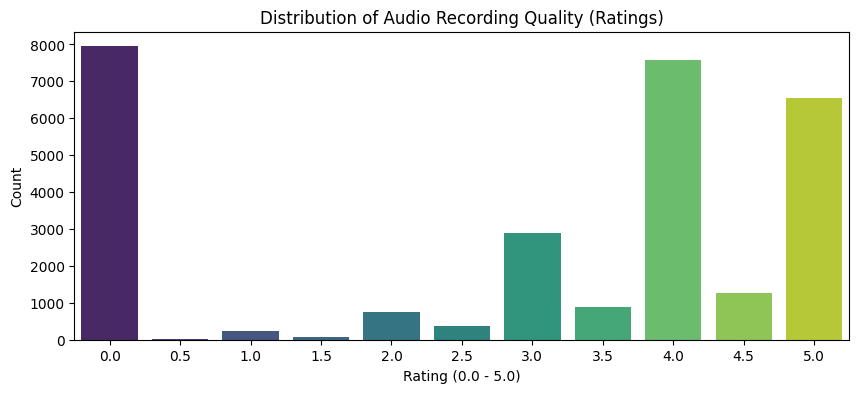

/tmp/ipykernel_2671/1911334164.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_authors.values, y=top_authors.index, palette='magma')


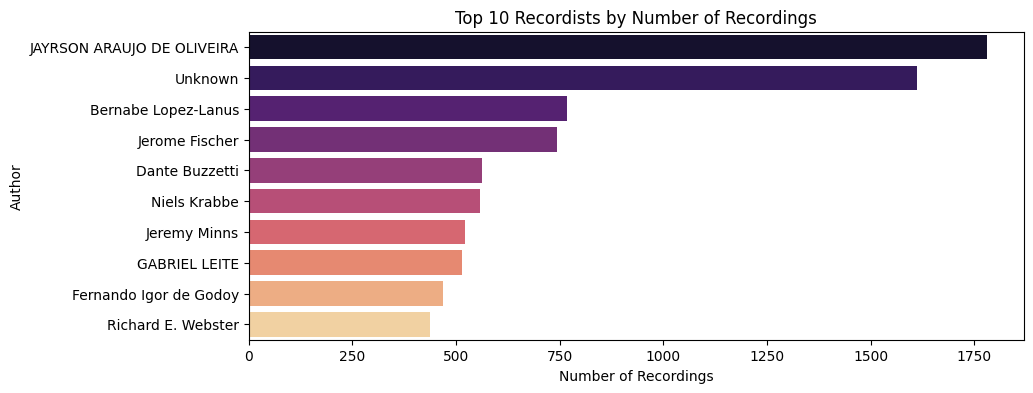


--- Sample Audio Details ---
Species: creoro1
Author: Joseph Tobias and Nathalie Seddon
Rating: 3.0
File: creoro1/XC74128.ogg


In [ ]:
import IPython.display as ipd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Rating (Kayıt Kalitesi) Dağılımı
plt.figure(figsize=(10, 4))
sns.countplot(data=df, x='rating', palette='viridis')
plt.title('Distribution of Audio Recording Quality (Ratings)')
plt.xlabel('Rating (0.0 - 5.0)')
plt.ylabel('Count')
plt.show()

# 2. Recordist (Kayıt Yapan Kişi) Dağılımı - Top 10
plt.figure(figsize=(10, 4))
top_authors = df['author'].value_counts().head(10)
sns.barplot(x=top_authors.values, y=top_authors.index, palette='magma')
plt.title('Top 10 Recordists by Number of Recordings')
plt.xlabel('Number of Recordings')
plt.ylabel('Author')
plt.show()

# 3. Rastgele Bir Sesi Dinleme
sample = df.sample(1).iloc[0]
sample_path = f"/content/data/train_audio/{sample['filename']}"

print(f"\n--- Sample Audio Details ---")
print(f"Species: {sample['primary_label']}")
print(f"Author: {sample['author']}")
print(f"Rating: {sample['rating']}")
print(f"File: {sample['filename']}")

# Sesi notebook üzerinde oynat
display(ipd.Audio(sample_path))

### 3.2. Recording Quality and Source Bias
A substantial volume of the audio files holds a `0.0` rating. Rather than indicating corrupted or unusable audio, this predominantly represents missing or "unrated" metadata. Additionally, "Unknown" is the second most frequent recordist. Filtering out these unrated files would lead to massive data loss. They will be retained to ensure the model learns to generalize across diverse, noisy, real-world recording conditions rather than overfitting to a specific high-quality microphone setup.

--- Number of Background Birds per Recording ---
num_secondary_birds
1     27744
2       510
3       181
4        52
5        29
0        25
6         9
7         7
8         3
9         2
11        1
10        1
Name: count, dtype: int64


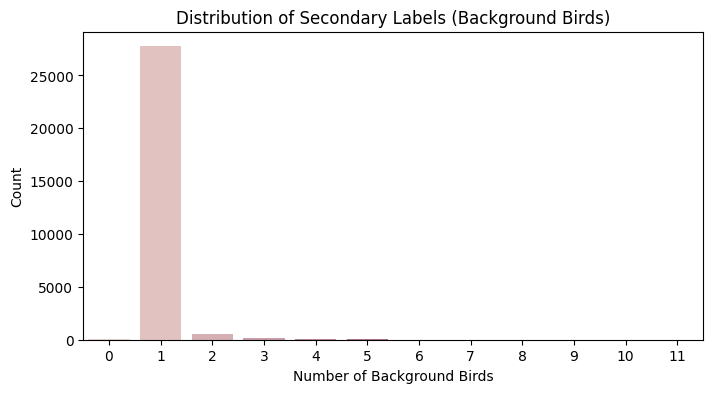


Highly noisy sample found in file: 126247/XC941297.ogg
Primary Bird: 126247
Background Birds: ['65448', '22976', '476538']


In [ ]:
import ast
import matplotlib.pyplot as plt
import seaborn as sns

# Convert string representation of lists to actual Python lists
df['secondary_labels_list'] = df['secondary_labels'].apply(ast.literal_eval)
df['num_secondary_birds'] = df['secondary_labels_list'].apply(len)

print("--- Number of Background Birds per Recording ---")
print(df['num_secondary_birds'].value_counts())

# Visualize the distribution
plt.figure(figsize=(8, 4))
sns.countplot(data=df, hue='num_secondary_birds', x='num_secondary_birds', legend=False)
plt.title('Distribution of Secondary Labels (Background Birds)')
plt.xlabel('Number of Background Birds')
plt.ylabel('Count')
plt.show()

# Example of a highly noisy label
noisy_sample = df[df['num_secondary_birds'] > 2].iloc[0]
print(f"\nHighly noisy sample found in file: {noisy_sample['filename']}")
print(f"Primary Bird: {noisy_sample['primary_label']}")
print(f"Background Birds: {noisy_sample['secondary_labels_list']}")

### 3.3. Background Birds and Class Noise
BirdCLEF recordings are wild soundscapes, meaning multiple species often vocalize simultaneously. If a 2-minute recording contains only 10 seconds of the `primary_label` and 110 seconds of `secondary_labels`, the 5-second random cropping strategy might extract a slice containing only the background species. Feeding this into the model as the primary label introduces significant class noise (contradictory/misclassified examples). For this initial baseline, noisy labels are used to establish a raw performance metric, but future iterations will require a Multi-Label Classification approach (e.g., using BCE Loss) to account for these secondary birds.

Plotting spectrogram for species: 1139490


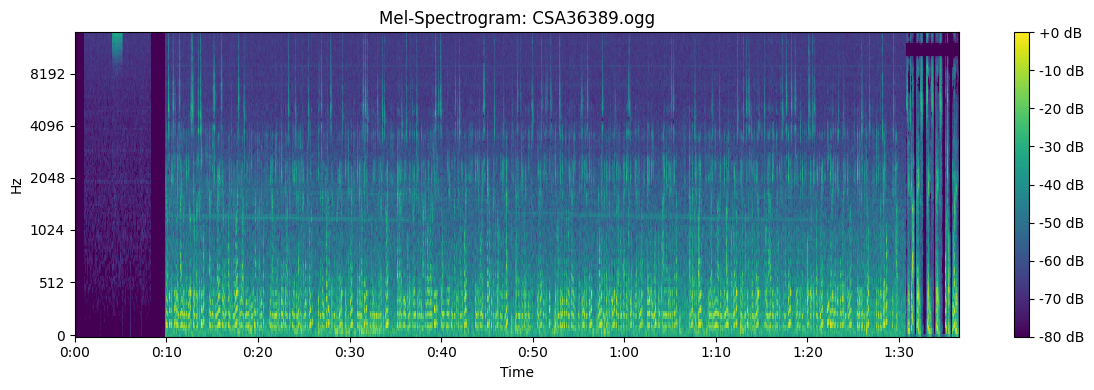

In [ ]:
import os
from GROUP21_CENG313.src.data import plot_mel_spectrogram

# Get a sample audio file path from the dataframe
sample_row = df.iloc[1]
sample_audio_path = os.path.join(data_dir, 'train_audio', sample_row['filename'])

# Call the function from src/data.py
print(f"Plotting spectrogram for species: {sample_row['primary_label']}")
plot_mel_spectrogram(sample_audio_path)

# 4. Preprocessing

Based on the EDA, the following preprocessing strategies are applied:

Cleaning: Geolocation (latitude, longitude) features are dropped as they are irrelevant to the audio-only CNN architecture.

Scaling & Transformation: Due to extreme length variations (ranging from ~1s to 443s), waveforms are dynamically cropped or padded to a uniform 5-second length during data loading. They are then transformed into 2D Mel-spectrograms (using 128 mel bands) directly on the GPU, providing a robust time-frequency representation.

Encoding: The categorical primary_label is transformed into numerical tensors using LabelEncoder.

Using device: cpu
Waveform batch shape: torch.Size([16, 1, 160000])
Mel-spectrogram batch shape: torch.Size([16, 1, 128, 313])


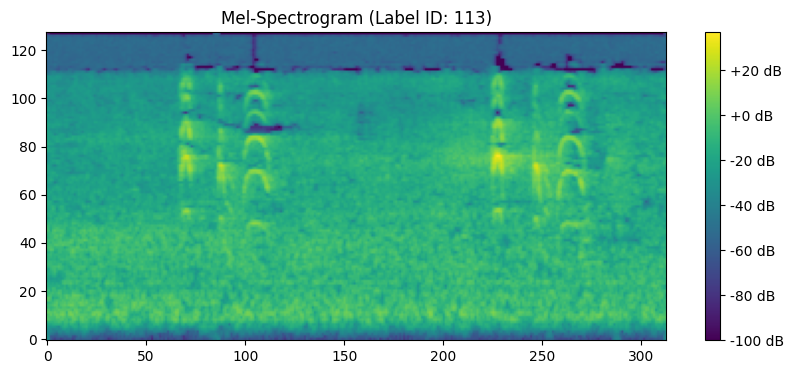

In [ ]:
import torch
import torchaudio.transforms as T
from torch.utils.data import DataLoader
from GROUP21_CENG313.src.data import BirdCLEFAudioDataset
import matplotlib.pyplot as plt

# Ensure GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Create Dataset and DataLoader
train_dataset = BirdCLEFAudioDataset(train_df, audio_dir='data/train_audio')
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2)

# Define GPU-based MelSpectrogram transformations
mel_transform = T.MelSpectrogram(
    sample_rate=32000,
    n_fft=2048,
    hop_length=512,
    n_mels=128
).to(device)

amplitude_to_db = T.AmplitudeToDB().to(device)

# Fetch a batch and apply transformations on GPU
for waveforms, labels in train_loader:
    waveforms = waveforms.to(device)
    labels = labels.to(device)

    # 1. Convert waveforms to Mel-spectrograms on GPU
    mels = mel_transform(waveforms)

    # 2. Convert to Decibel scale on GPU
    mels_db = amplitude_to_db(mels)

    print(f"Waveform batch shape: {waveforms.shape}")
    print(f"Mel-spectrogram batch shape: {mels_db.shape}")

    # Plot the first item in the batch
    plt.figure(figsize=(10, 4))
    plt.imshow(mels_db[0, 0].cpu().numpy(), aspect='auto', origin='lower', cmap='viridis')
    plt.title(f"Mel-Spectrogram (Label ID: {labels[0].item()})")
    plt.colorbar(format='%+2.0f dB')
    plt.show()
    break

* **Scaling & Transformation (Mel-Spectrogram Generation):**
Due to extreme length variations, waveforms are dynamically cropped or padded to a uniform 5-second length during data loading. Crucially, raw 1D audio waveforms are highly dimensional and lack explicit frequency-domain structures, making them difficult for standard CNNs to learn from.

To overcome this, raw waveforms are transformed into 2D Mel-spectrograms (using 128 mel bands) directly on the GPU. As shown in the generated plot, this transformation converts audio into an image-like format `(1, 128, 313)` where the x-axis represents time, the y-axis represents mel-scaled frequencies, and color intensity represents amplitude (dB).
**Interpretation of the Plot:** The distinct, arch-like vertical yellow patterns clearly visible in the spectrogram represent the specific harmonic frequencies of the bird's call. By feeding this 2D representation into a CNN, the bird's vocalization can be treated as spatial edges and shapes, leveraging standard image classification techniques to recognize these species-specific acoustic signatures.

## 5. Baseline Model (ResNet-18)

For the baseline, a pre-trained ResNet-18 architecture modified to accept single-channel Mel-spectrograms is utilized. An 80/20 train_test_split with stratification is performed to ensure minority classes are represented in the validation set. Cross-Entropy loss and the Adam optimizer are used without advanced augmentation to establish a raw performance benchmark.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchaudio.transforms as T
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from GROUP21_CENG313.src.data import BirdCLEFAudioDataset
from GROUP21_CENG313.src.models import BirdCLEFResNet
from GROUP21_CENG313.src.engine import train_one_epoch, evaluate

# 1. Label Encoding ve Train/Val Split (Eğer EDA'da yapmadıysan)
encoder = LabelEncoder()
df['label_id'] = encoder.fit_transform(df['primary_label'])
num_classes = len(encoder.classes_)

train_df, val_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label_id'])

# 2. Dataset ve DataLoader (Yerel SSD yolu ile)
local_audio_dir = '/content/data/train_audio'
train_dataset = BirdCLEFAudioDataset(train_df, audio_dir=local_audio_dir)
val_dataset = BirdCLEFAudioDataset(val_df, audio_dir=local_audio_dir)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

# 3. Model, Loss, Optimizer
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on: {device}")

model = BirdCLEFResNet(num_classes=num_classes, pretrained=True).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# 4. GPU-based Audio Transforms
mel_transform = T.MelSpectrogram(sample_rate=32000, n_fft=2048, hop_length=512, n_mels=128).to(device)
amplitude_to_db = T.AmplitudeToDB().to(device)

# 5. Baseline Run
num_epochs = 10
for epoch in range(num_epochs):
    print(f"\nEpoch {epoch+1}/{num_epochs}")
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device, mel_transform, amplitude_to_db)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device, mel_transform, amplitude_to_db)

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {(train_acc:.4f)}")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {(val_acc:.4f)}")

Training on: cuda

Epoch 1/10


Validation: 100%|██████████| 179/179 [01:10<00:00,  2.52it/s, val_loss=3.0270, val_acc=0.3331]


Train Loss: 3.4688 | Train Acc: 0.2617
Val Loss: 3.0270 | Val Acc: 0.3331

Epoch 2/10


Validation: 100%|██████████| 179/179 [01:11<00:00,  2.52it/s, val_loss=2.4537, val_acc=0.4644]


Train Loss: 2.4411 | Train Acc: 0.4571
Val Loss: 2.4537 | Val Acc: 0.4644

Epoch 3/10


Validation: 100%|██████████| 179/179 [01:10<00:00,  2.54it/s, val_loss=2.1302, val_acc=0.5416]


... (11 outputs left out)

Validation: 100%|██████████| 179/179 [01:10<00:00,  2.55it/s, val_loss=1.7506, val_acc=0.6300]


Train Loss: 1.2770 | Train Acc: 0.7043
Val Loss: 1.7506 | Val Acc: 0.6300

Epoch 10/10


Validation: 100%|██████████| 179/179 [01:10<00:00,  2.55it/s, val_loss=1.7912, val_acc=0.6270]

Train Loss: 1.1896 | Train Acc: 0.7204
Val Loss: 1.7912 | Val Acc: 0.6270


# 6. Kaggle submission
*Note: Competition closed — evaluated on a held-out split.*

Since BirdCLEF is a strict Code Competition with a hidden test set and no longer accepts late submissions, the ResNet-18 baseline was evaluated on a 20% held-out stratified validation split.

* **Baseline Score:** ~0.6335 Macro-Accuracy (Validation)
* **Leaderboard Comparison:** The top-ranking solutions on the Kaggle leaderboard achieved scores around 0.933 (Public) and 0.930 (Private), with the top 25 teams scoring above 0.905. The naive baseline successfully extracts fundamental acoustic features but is approximately 30% behind the top-tier solutions. This massive performance gap is a direct consequence of unmitigated class imbalance and background label noise, which will be systematically addressed in Assignment 2.


## 7. Conclusion and Baseline Evaluation
The baseline ResNet-18 model achieved a training accuracy of ~72.04% and a validation accuracy of ~63.35% over 10 epochs. The validation loss reached its minimum around epoch 8 (1.7549) before starting to increase, indicating the onset of overfitting.

For a 206-class classification problem, reaching >63% validation accuracy with a naive baseline (no augmentation, no class balancing, basic random cropping) is a strong starting point. However, the plateauing validation metrics directly reflect the data quality issues diagnosed during the EDA:
1. **Class Imbalance:** The model is likely overfitting to the heavily represented majority classes while failing on the data-scarce minority classes.
2. **Cropping Bias:** Random 5-second crops from long audio files inevitably capture segments containing only background noise or secondary species, feeding contradictory labels to the model.

**Next Steps (Proposed Solution):**
In the subsequent phase, these bottlenecks will be addressed by implementing Advanced Audio Augmentation, Weighted/Focal Loss functions to penalize majority class dominance, and a robust Inference Windowing (Chunking) + Max Pooling strategy to ensure no temporal audio features are missed.